In [110]:
import pandas as pd
import numpy as np

In [111]:
df = pd.read_csv('../03-classification/course_lead_scoring_2026.csv')
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [112]:
# Data prep
categorical_fields = ['lead_source', 'industry', 'employment_status', 'location']
numerical_fields = ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']

df[categorical_fields] = df[categorical_fields].fillna('NA')
df[numerical_fields] = df[numerical_fields].fillna(0.0)

In [113]:
from sklearn.model_selection import train_test_split

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

In [114]:
from sklearn.metrics import roc_auc_score

In [115]:
# Q1
y = df.converted

for field in numerical_fields:
  y_pred = df[field]
  score = roc_auc_score(y, y_pred)
  print(field, score)


annual_income 0.60979163604804
number_of_courses_viewed 0.7228486308497142
interaction_count 0.7623573499695493
lead_score 0.7872284404317591


In [116]:
from sklearn.feature_extraction import DictVectorizer

In [117]:
# Q2
def train(df_train, y_train, C=1.0):
  dicts = df_train[categorical_fields + numerical_fields].to_dict(orient='records')

  dv = DictVectorizer(sparse=False)
  X_train = dv.fit_transform(dicts)

  model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
  model.fit(X_train, y_train)
  
  return dv, model

In [118]:
from sklearn.linear_model import LogisticRegression


In [119]:
def predict(df, dv, model):
  dicts = df[categorical_fields + numerical_fields].to_dict(orient='records')

  X = dv.transform(dicts)
  y_pred = model.predict_proba(X)[:, 1]

  return y_pred

In [120]:
y_train = df_train.converted.to_numpy()
y_val = df_val.converted.to_numpy()

dv, model = train(df_train, y_train)

In [121]:
y_val_pred = predict(df_val, dv, model)
y_val, y_val_pred

(array([0, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0,
        1, 0, 1, 0, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1,
        1, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 1, 0, 1, 0, 1, 0, 0, 1,
        1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 0, 1, 0, 1,
        1, 0, 0, 1, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 1, 0, 0,
        1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 0, 1, 0, 1, 1, 1, 0, 0,
        0, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 0, 1, 1, 1, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1,
        0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 1, 1, 1, 0, 0, 1, 0, 0, 1, 1, 1, 0,
        0, 1, 0, 1, 1, 1, 0, 1, 0, 0, 1, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0, 0,
        1, 1, 1, 0, 0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0,
        1, 0, 1, 1, 1, 1, 1, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        0, 0, 1, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 0, 0, 0, 1, 0, 0, 0, 

In [122]:
roc_auc_score(y_val, y_val_pred)

0.7318222288173319

In [123]:
# Q3
from sklearn.metrics import precision_score, recall_score

In [124]:
thresholds = np.linspace(0, 1, 101)

precisions = []
recalls = []

for threshold in thresholds:
  y_pred = y_val_pred > threshold
  precisions.append(precision_score(y_val, y_pred))
  recalls.append(recall_score(y_val, y_pred))


/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/usr/local/python/3

In [125]:
import matplotlib.pyplot as plt

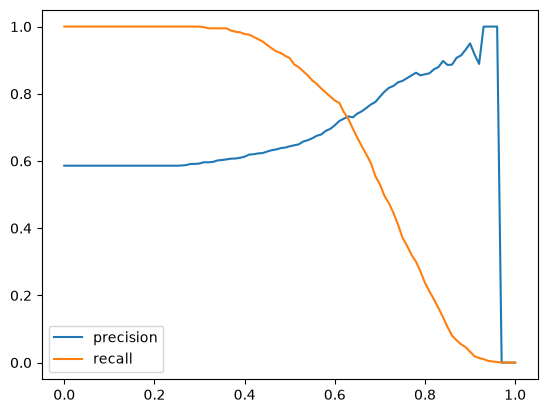

In [126]:
plt.plot(thresholds, precisions, label='precision')
plt.plot(thresholds, recalls, label='recall')
plt.legend()

In [127]:
from sklearn.metrics import f1_score

In [128]:
# Q4
results = []

for threshold in thresholds:
  y_pred = y_val_pred > threshold
  f1 = f1_score(y_val, y_pred, zero_division=0)
  results.append({
    'threshold': threshold,
    'f1': f1
  })

results

[{'threshold': np.float64(0.0), 'f1': 0.7389659520807061},
 {'threshold': np.float64(0.01), 'f1': 0.7389659520807061},
 {'threshold': np.float64(0.02), 'f1': 0.7389659520807061},
 {'threshold': np.float64(0.03), 'f1': 0.7389659520807061},
 {'threshold': np.float64(0.04), 'f1': 0.7389659520807061},
 {'threshold': np.float64(0.05), 'f1': 0.7389659520807061},
 {'threshold': np.float64(0.06), 'f1': 0.7389659520807061},
 {'threshold': np.float64(0.07), 'f1': 0.7389659520807061},
 {'threshold': np.float64(0.08), 'f1': 0.7389659520807061},
 {'threshold': np.float64(0.09), 'f1': 0.7389659520807061},
 {'threshold': np.float64(0.1), 'f1': 0.7389659520807061},
 {'threshold': np.float64(0.11), 'f1': 0.7389659520807061},
 {'threshold': np.float64(0.12), 'f1': 0.7389659520807061},
 {'threshold': np.float64(0.13), 'f1': 0.7389659520807061},
 {'threshold': np.float64(0.14), 'f1': 0.7389659520807061},
 {'threshold': np.float64(0.15), 'f1': 0.7389659520807061},
 {'threshold': np.float64(0.16), 'f1': 0.7

In [129]:
df_f1 = pd.DataFrame(results)
max_idx = df_f1.f1.idxmax()
df_f1.iloc[max_idx]

threshold    0.410000
f1           0.757616
Name: 41, dtype: float64

In [130]:
# Q5
from sklearn.model_selection import KFold

In [131]:
def kfold(C=1.0):
  kfold = KFold(n_splits=5, shuffle=True, random_state=1)

  scores = []

  for train_idx, val_idx in kfold.split(df_full_train):
    df_train = df_full_train.iloc[train_idx]
    df_val = df_full_train.iloc[val_idx]

    y_train = df_train.converted
    y_val = df_val.converted

    dv, model = train(df_train, y_train, C)
    y_pred = predict(df_val, dv, model)

    auc = roc_auc_score(y_val, y_pred)
    scores.append(auc)

  print('C=%s %.3f +- %.3f' % (C, np.mean(scores), np.std(scores)))

In [132]:
kfold()

C=1.0 0.732 +- 0.007


In [133]:
# Q6
for C in [0.000001, 0.001, 1]:
  kfold(C)

C=1e-06 0.617 +- 0.019
C=0.001 0.749 +- 0.010
C=1 0.732 +- 0.007
